# 8. Hardenability: why some steels change so much on air cooling

Whether air cooling gives ferrite + pearlite or bainite and martensite is a hardenability question. This
notebook shows (1) Grossmann's ideal critical diameter D_I (ASTM A255 factors) against the model's air-cooled
microstructures, (2) the model against the SAE Jominy hardenability bands of the H-steels, and (3) the
Bayesian calibration of the bainite reaction on those bands, with the test of whether it transfers to data
it never saw.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3g}")
R = ROOT / "results"; FIG = ROOT / "figures"
def fig(name, width=1000):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

In [2]:
pd.read_csv(R / "s08_ideal_diameter_summary.csv")

,DI_mm_from,DI_mm_to,grades,median_hard_phase_AC25,share_over_50pct_B_M_AC25,median_dUTS_AC25_MPa
0,0,40,170,0,0,40.5
1,40,60,47,0,0.0638,118
2,60,80,25,0.247,0.36,139
3,80,100,8,0.0099,0.125,210
4,100,130,12,0.83,0.833,256
5,130,1000,9,0.95,0.889,408


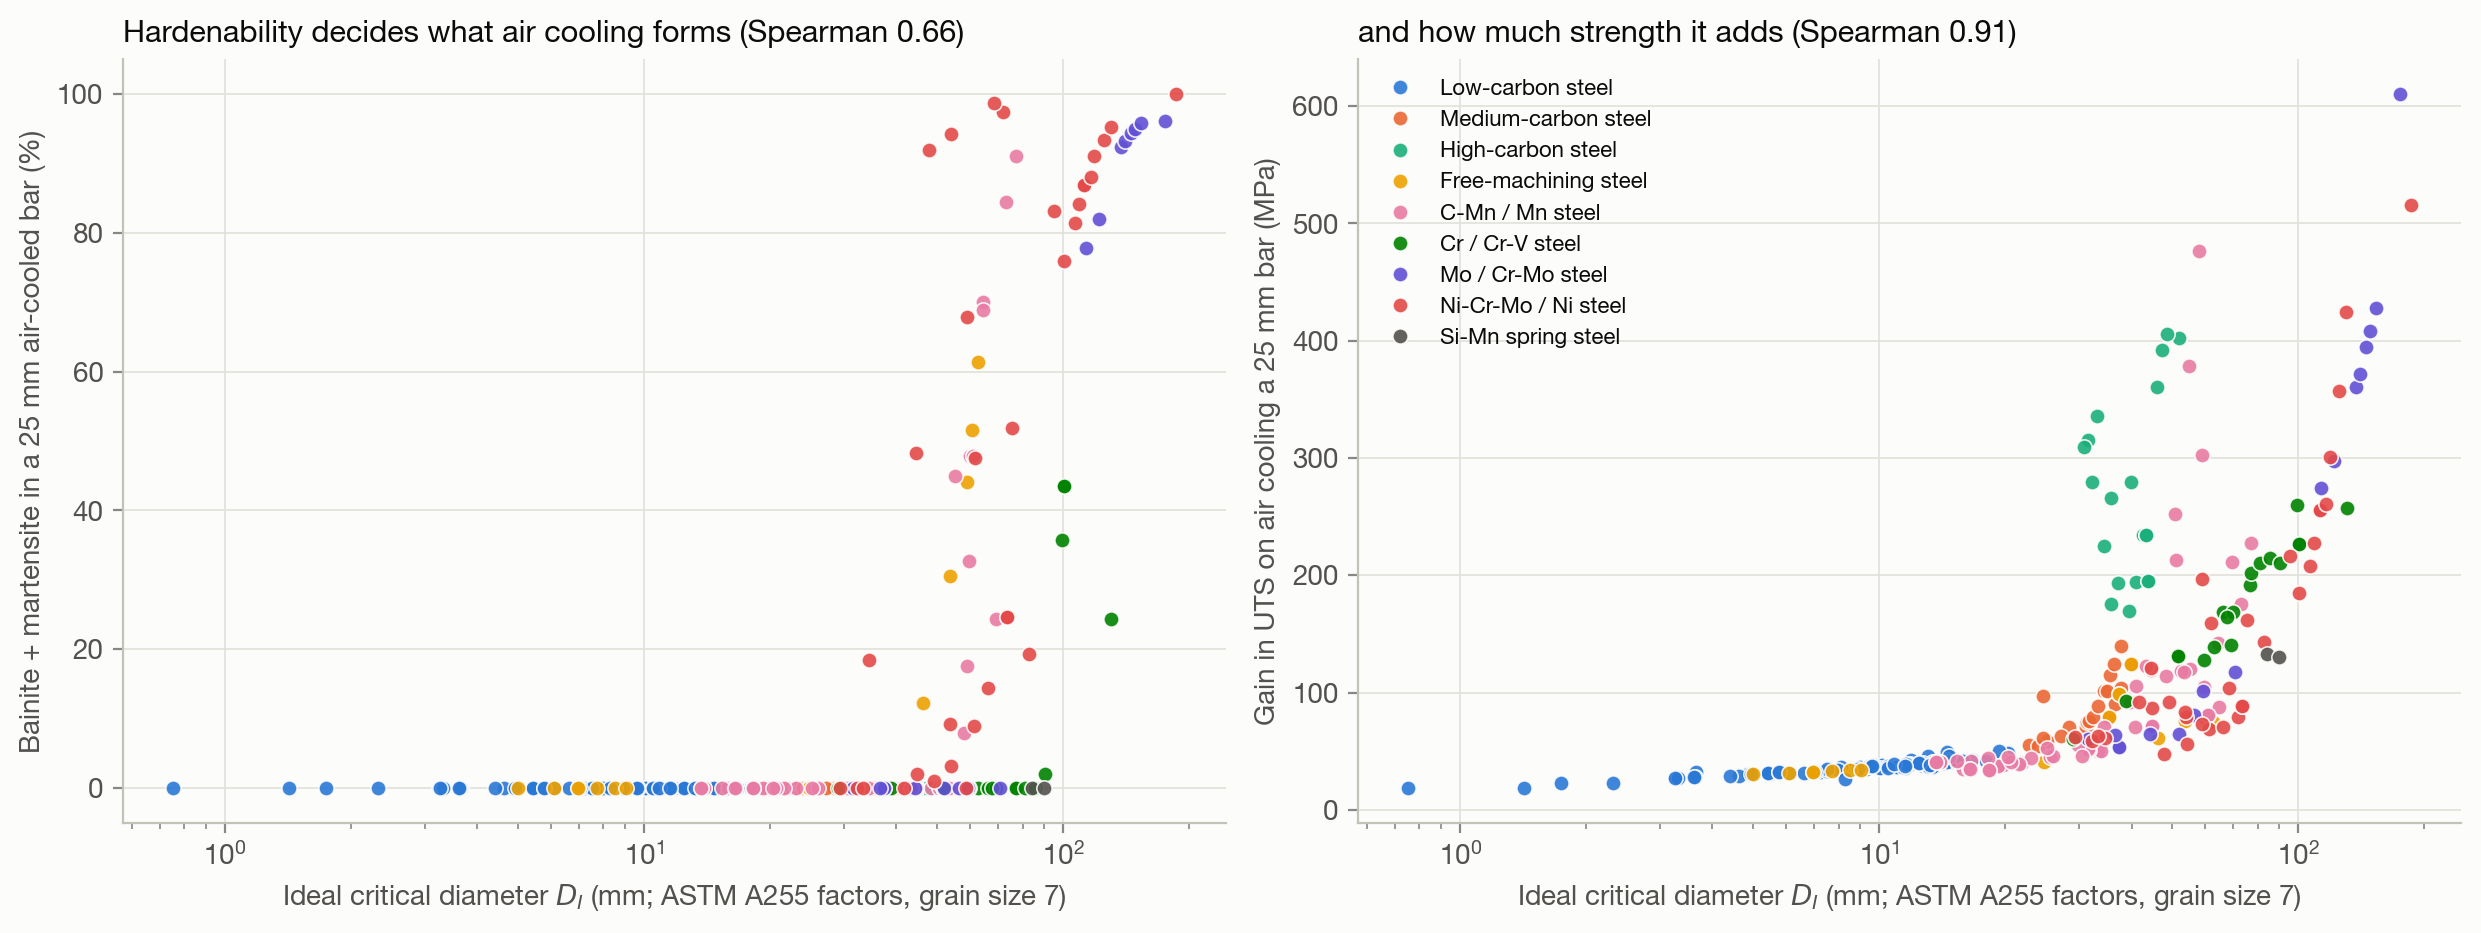

In [3]:
fig("fig25_hardenability_vs_air_cooling", 950)

## Jominy end-quench against the SAE H-bands
The Jominy bar is solved by 1-D conduction; its water-jet coefficient is fitted to the cooling-rate scale of
the ASM combined hardenability charts. The published Li constants are right at the quenched end and too
hardenable from J5 on.

In [4]:
pd.read_csv(R / "s08_jominy_cooling_rates.csv")

,J,distance_mm,rate_as_printed,cooling_rate_C_per_s_at_700C,source,model_rate,ratio,h_q_W_m2K
0,5,7.94,55 degF/s,30.6,Metallus (2024) Practical Data for Metallurgis...,28.6,0.936,7.97e+03
1,10,15.9,25 degF/s,13.9,Metallus (2024) Practical Data for Metallurgis...,12,0.862,7.97e+03
2,15,23.8,12 degF/s,6.67,Metallus (2024) Practical Data for Metallurgis...,7.09,1.06,7.97e+03
3,20,31.8,7 degF/s,3.89,Metallus (2024) Practical Data for Metallurgis...,4.89,1.26,7.97e+03
4,27,42.9,290 degF/min,2.69,Metallus (2024) Practical Data for Metallurgis...,3.36,1.25,7.97e+03
5,48,76.2,200 degF/min,1.85,Metallus (2024) Practical Data for Metallurgis...,1.82,0.983,7.97e+03


In [5]:
m = pd.read_csv(R / "s08_jominy_metrics.csv"); m[m.grades == "non-boron grades"]

,distances,n,RMSE_HRC,bias_HRC,inside_band,kinetics,grades
0,all distances,1040,10.1,6.97,0.542,published Li et al. constants,non-boron grades
1,J1-J4 (quenched end),256,4.13,0.574,0.852,published Li et al. constants,non-boron grades
2,J5-J16,549,9.83,7.66,0.556,published Li et al. constants,non-boron grades
3,J18-J32 (air-cooling range),235,14.5,12.3,0.174,published Li et al. constants,non-boron grades
8,all distances,1040,5.63,0.505,0.802,calibrated on the H-bands,non-boron grades
9,J1-J4 (quenched end),256,5.37,-2.9,0.723,calibrated on the H-bands,non-boron grades
10,J5-J16,549,4.84,0.95,0.843,calibrated on the H-bands,non-boron grades
11,J18-J32 (air-cooling range),235,7.35,3.17,0.791,calibrated on the H-bands,non-boron grades
16,all distances,1040,5.6,0.622,0.792,calibrated on the H-bands + dilatometry starts,non-boron grades
17,J1-J4 (quenched end),256,5.58,-3.07,0.703,calibrated on the H-bands + dilatometry starts,non-boron grades


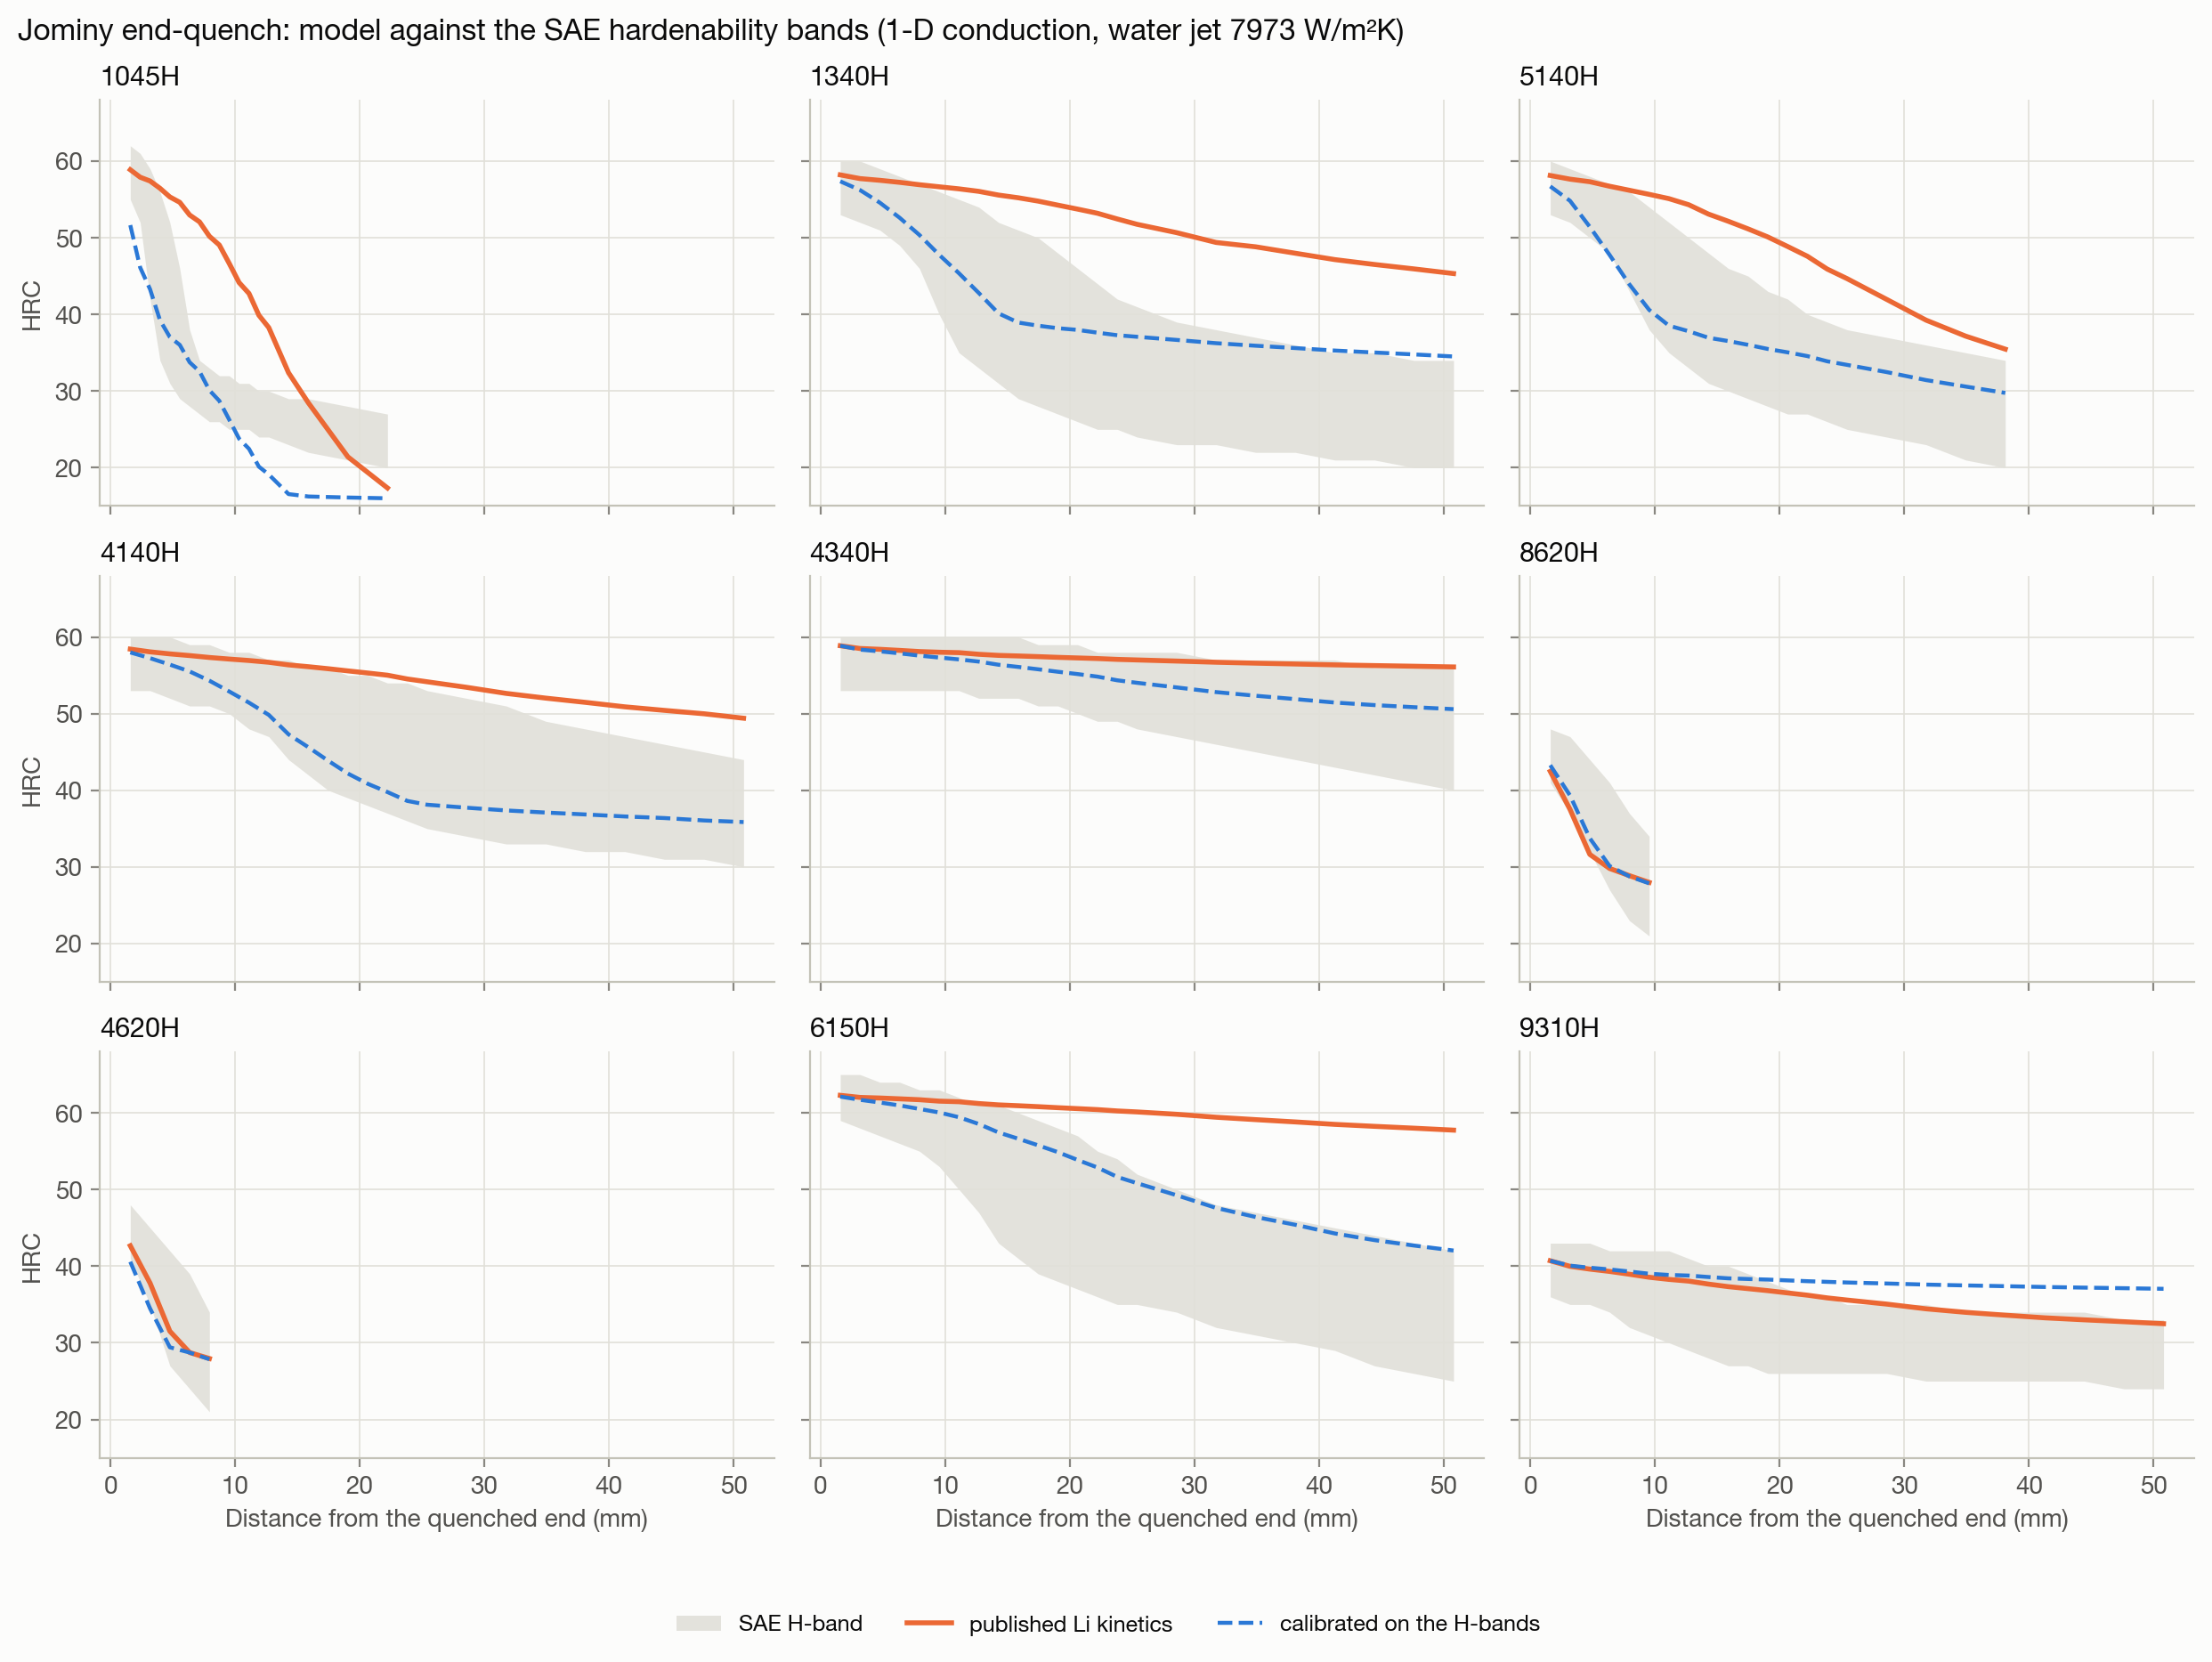

In [6]:
fig("fig29_jominy_hbands", 900)

## Calibration, cross-validation and transfer
The calibration changes only the bainite reaction (it starts lower and proceeds faster below that); the
H-bands do not constrain the ferrite and pearlite rates. Grade-grouped cross-validation, then the transfer
table: the calibrated kinetics against every independent dataset.

In [7]:
pd.read_csv(R / "s08_kinetic_calibration_posterior.csv")

,parameter,H-bands MAP,H-bands Laplace sd,H-bands + dilatometry MAP,H-bands factor,joint factor
0,ln_f_ferrite,-0.00559,1e+03,0.721,0.994,2.06
1,ln_f_pearlite,-0.000494,8.05,-0.352,1,0.704
2,ln_f_bainite,4.37,2.25,4.48,79.4,88.5
3,dBs_C,-107,5.62,-109,-107,-109
4,ln_sigma_model,1.49,6.24,1.46,4.44,4.29


In [8]:
pd.read_csv(R / "s08_kinetic_calibration_cv_metrics.csv")

,distances,n,RMSE_HRC,bias_HRC,inside_band,kinetics
0,all distances,1040,10.1,6.97,0.542,HRC_published
1,J1-J4 (quenched end),256,4.13,0.574,0.852,HRC_published
2,J5-J16,549,9.83,7.66,0.556,HRC_published
3,J18-J32 (air-cooling range),235,14.5,12.3,0.174,HRC_published
4,all distances,1040,5.87,0.673,0.781,HRC_calibrated_cv
5,J1-J4 (quenched end),256,5.46,-2.94,0.711,HRC_calibrated_cv
6,J5-J16,549,5.05,1.07,0.827,HRC_calibrated_cv
7,J18-J32 (air-cooling range),235,7.79,3.67,0.749,HRC_calibrated_cv


In [9]:
pd.read_csv(R / "s08_kinetic_calibration_transfer.csv").set_index("kinetics").T

kinetics,published Li et al. constants,calibrated on the H-bands,calibrated on the H-bands + dilatometry starts
H-band_RMSE_HRC_non_boron,10.1,5.63,5.6
ferrite_start_MAE_C,15.7,15.7,19
pearlite_start_MAE_C,22.6,22.6,20.9
bainite_start_bias_C,67.3,-19.9,-27.7
martensite_start_MAE_C,10.3,7.42,7.42
dilatometry_HB_RMSE_le_5Ks,31.8,56.7,57.8
pearlite_fraction_MAE_furnace,4.27,4.27,4.24
pearlite_fraction_MAE_air,21.8,19,25.1
handbook_HB_RMSE_best_bar,20.7,22.6,26.5
handbook_best_bar_mm,65,50,35
